In [ ]:
import pandas as pd

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

In [45]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
DATA_PATH = Path("../data/raw/events.csv")

print(DATA_PATH.exists())

True


In [3]:
events = pd.read_csv(DATA_PATH)

events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [4]:
events.shape

(2756101, 5)

In [5]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 116.1 MB


In [6]:
events.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,2756101.00,NaN,NaN,NaN,1436424488348.10,3366312180.01,1430622004384.00,1433478194792.00,1436453013599.00,1439225105168.00,1442545187788.00
visitorid,2756101.00,NaN,NaN,NaN,701922.88,405687.52,0.00,350566.00,702060.00,1053437.00,1407579.00
event,2756101,3,view,2664312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
itemid,2756101.00,NaN,NaN,NaN,234922.48,134195.43,3.00,118120.00,236067.00,350715.00,466867.00
transactionid,22457.00,NaN,NaN,NaN,8826.50,5099.00,0.00,4411.00,8813.00,13224.00,17671.00


In [7]:
events.columns.tolist()

['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

In [8]:
events.isna().sum()

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

In [9]:
events.duplicated().sum()

np.int64(460)

In [10]:
events["event"].value_counts(dropna=False)

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

In [11]:
events["timestamp"].agg(["min", "max"])

min    1430622004384
max    1442545187788
Name: timestamp, dtype: int64

In [12]:
datetime_test = pd.to_datetime(
    events["timestamp"].head(1000),
    unit="ms",
    utc=True
)

datetime_test.head()

0   2015-06-02 05:02:12.117+00:00
1   2015-06-02 05:50:14.164+00:00
2   2015-06-02 05:13:19.827+00:00
3   2015-06-02 05:12:35.914+00:00
4   2015-06-02 05:02:17.106+00:00
Name: timestamp, dtype: datetime64[us, UTC]

In [13]:
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events["datetime"].agg(["min", "max"])

min   2015-05-03 03:00:04.384+00:00
max   2015-09-18 02:59:47.788+00:00
Name: datetime, dtype: datetime64[us, UTC]

In [14]:
print("Unique users:", events["visitorid"].nunique())
print("Unique items:", events["itemid"].nunique())
print("Unique transactions:", events["transactionid"].nunique())

Unique users: 1407580
Unique items: 235061
Unique transactions: 17672


In [15]:
events.groupby("event").agg(
    total_events=("event", "size"),
    unique_users=("visitorid", "nunique"),
    unique_items=("itemid", "nunique"),
    transactions=("transactionid", "nunique")
)

,total_events,unique_users,unique_items,transactions
event,,,,
addtocart,69332,37722,23903,0
transaction,22457,11719,12025,17672
view,2664312,1404179,234838,0


In [16]:
events.groupby("event").agg(
    total_rows=("event", "size"),
    missing_transactionid=("transactionid", lambda x: x.isna().sum()),
    non_missing_transactionid=("transactionid", lambda x: x.notna().sum()),
    unique_transactionid=("transactionid", "nunique")
)

,total_rows,missing_transactionid,non_missing_transactionid,unique_transactionid
event,,,,
addtocart,69332,69332,0,0
transaction,22457,0,22457,17672
view,2664312,2664312,0,0


In [17]:
transactions = events[events["event"] == "transaction"]

transaction_summary = transactions.groupby("transactionid").agg(
    visitors=("visitorid", "nunique"),
    items=("itemid", "nunique"),
    rows=("itemid", "size")
)

transaction_summary.describe()

,visitors,items,rows
count,17672.00,17672.00,17672.00
mean,1.00,1.26,1.27
std,0.00,0.94,0.97
min,1.00,1.00,1.00
25%,1.00,1.00,1.00
50%,1.00,1.00,1.00
75%,1.00,1.00,1.00
max,1.00,31.00,31.00


In [18]:
transaction_summary.sort_values(
    "items",
    ascending=False
).head(10)

,visitors,items,rows
transactionid,,,
7063.00,1,31,31
765.00,1,28,28
2753.00,1,23,23
6993.00,1,21,21
17211.00,1,17,17
11927.00,1,17,17
4227.00,1,16,16
17493.00,1,16,16
13690.00,1,16,16


In [19]:
duplicates = events[events.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))

duplicates.groupby("event").size()

Rows involved in duplicates: 918


event
addtocart    732
view         186
dtype: int64

In [20]:
duplicates.sort_values(
    ["visitorid", "timestamp"]
).head(20)

,timestamp,visitorid,event,itemid,transactionid,datetime
1041548,1440547735041,745,addtocart,246164,NaN,2015-08-26 00:08:55.041+00:00
1051024,1440547735041,745,addtocart,246164,NaN,2015-08-26 00:08:55.041+00:00
301904,1434501277715,3926,addtocart,323347,NaN,2015-06-17 00:34:37.715+00:00
319376,1434501277715,3926,addtocart,323347,NaN,2015-06-17 00:34:37.715+00:00
113491,1433611737367,10162,addtocart,146661,NaN,2015-06-06 17:28:57.367+00:00
124035,1433611737367,10162,addtocart,146661,NaN,2015-06-06 17:28:57.367+00:00
1965082,1432707397977,12046,addtocart,205663,NaN,2015-05-27 06:16:37.977+00:00
1983425,1432707397977,12046,addtocart,205663,NaN,2015-05-27 06:16:37.977+00:00
1166547,1441151647762,12560,addtocart,272976,NaN,2015-09-01 23:54:07.762+00:00
1167841,1441151647762,12560,addtocart,272976,NaN,2015-09-01 23:54:07.762+00:00


In [21]:
duplicate_groups = (
    events.groupby(
        ["timestamp", "visitorid", "event", "itemid", "transactionid"],
        dropna=False
    )
    .size()
    .reset_index(name="copies")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["copies"] > 1
]

duplicate_groups["copies"].value_counts().sort_index()


copies
2    456
3      2
Name: count, dtype: int64

In [22]:
duplicate_groups.groupby("event").agg(
    duplicate_groups=("copies", "size"),
    extra_rows=("copies", lambda x: (x - 1).sum()),
    max_copies=("copies", "max")
)

,duplicate_groups,extra_rows,max_copies
event,,,
addtocart,366,366,2
view,92,94,3


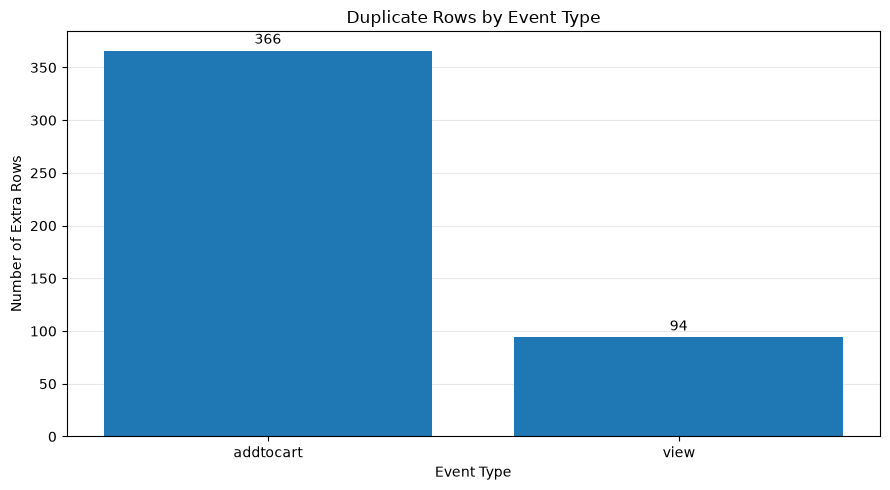

In [49]:
duplicate_summary = (
    duplicate_groups.groupby("event")
    .agg(
        duplicate_groups=("copies", "size"),
        extra_rows=("copies", lambda x: (x - 1).sum())
    )
    .sort_values("extra_rows", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    duplicate_summary.index,
    duplicate_summary["extra_rows"]
)

ax.set_title("Duplicate Rows by Event Type")
ax.set_xlabel("Event Type")
ax.set_ylabel("Number of Extra Rows")

ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(
        lambda x, _: f"{x:,.0f}".replace(",", " ")
    )
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}".replace(",", " "),
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dq_duplicates_by_event.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
transactions.duplicated(
    subset=["transactionid", "itemid"]
).sum()

np.int64(134)

In [24]:
transactions[
    transactions.duplicated(
        subset=["transactionid", "itemid"],
        keep=False
    )
].sort_values(["transactionid", "itemid"]).head(20)

,timestamp,visitorid,event,itemid,transactionid,datetime
398271,1434834774043,1320211,transaction,258089,127.00,2015-06-20 21:12:54.043+00:00
402722,1434834652131,1320211,transaction,258089,127.00,2015-06-20 21:10:52.131+00:00
396586,1434834652131,1320211,transaction,351861,127.00,2015-06-20 21:10:52.131+00:00
402639,1434834774152,1320211,transaction,351861,127.00,2015-06-20 21:12:54.152+00:00
1384572,1442064558136,121481,transaction,140532,143.00,2015-09-12 13:29:18.136+00:00
1384596,1442064505142,121481,transaction,140532,143.00,2015-09-12 13:28:25.142+00:00
1134371,1440982737644,1165148,transaction,188669,442.00,2015-08-31 00:58:57.644+00:00
1139336,1440982612017,1165148,transaction,188669,442.00,2015-08-31 00:56:52.017+00:00
539535,1435331650457,1165346,transaction,368113,931.00,2015-06-26 15:14:10.457+00:00
545749,1435331650332,1165346,transaction,368113,931.00,2015-06-26 15:14:10.332+00:00


In [25]:
repeated_items = (
    transactions.groupby(["transactionid", "itemid"])
    .agg(
        rows=("timestamp", "size"),
        unique_timestamps=("timestamp", "nunique"),
        unique_visitors=("visitorid", "nunique"),
        first_timestamp=("timestamp", "min"),
        last_timestamp=("timestamp", "max")
    )
    .query("rows > 1")
    .sort_values("rows", ascending=False)
)

print("Repeated transaction-item groups:", len(repeated_items))
print("Extra rows:", (repeated_items["rows"] - 1).sum())

repeated_items.head(15)

Repeated transaction-item groups: 123
Extra rows: 134


rows  unique_timestamps  unique_visitors  \
transactionid itemid                                             
2212.00       325772     4                  4                1   
3011.00       259147     3                  3                1   
4904.00       255725     3                  3                1   
7500.00       81944      3                  3                1   
12847.00      98633      3                  3                1   
              91547      3                  3                1   
15607.00      294438     3                  3                1   
3485.00       428891     3                  3                1   
              387697     3                  3                1   
12363.00      275354     3                  3                1   
9562.00       111530     2                  2                1   
              191634     2                  2                1   
127.00        258089     2                  2                1   
9562.00       335459     2                  2                1   
9476.00       350103     2                  2                1   

                      first_timestamp  last_timestamp  
transactionid itemid                                   
2212.00       325772    1436138344506   1436139416639  
3011.00       259147    1436073946489   1436084558860  
4904.00       255725    1434739955255   1434739955508  
7500.00       81944     1436287259670   1436287287799  
12847.00      98633     1437068450728   1437086666342  
              91547     1437068450681   1437086666342  
15607.00      294438    1431545197044   1431545287122  
3485.00       428891    1441318376634   1441318857450  
              387697    1441318376636   1441318857466  
12363.00      275354    1439823500187   1439823546756  
9562.00       111530    1434519461894   1434519489356  
              191634    1434519461879   1434519489356  
127.00        258089    1434834652131   1434834774043  
9562.00       335459    1434519461879   1434519489340  
9476.00       350103    1436051262199   1436051324930

In [ ]:
print("Timestamp missing:", events["timestamp"].isna().sum())
print("Timestamp zero:", (events["timestamp"] == 0).sum())
print("Negative timestamps:", (events["timestamp"] < 0).sum())

print("Datetime min:", events["datetime"].min())
print("Datetime max:", events["datetime"].max())

Timestamp missing: 0
Timestamp zero: 0
Negative timestamps: 0
Datetime min: 2015-05-03 03:00:04.384000+00:00
Datetime max: 2015-09-18 02:59:47.788000+00:00


In [27]:
user_activity = events.groupby("visitorid").agg(
    total_events=("event", "size"),
    unique_items=("itemid", "nunique"),
    first_seen=("timestamp", "min"),
    last_seen=("timestamp", "max")
)

user_activity.describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
)

,total_events,unique_items,first_seen,last_seen
count,1407580.00,1407580.00,1407580.00,1407580.00
mean,1.96,1.52,1436437002513.63,1436642244858.69
std,12.58,7.14,3386907355.95,3383495266.13
min,1.00,1.00,1430622004384.00,1430622011289.00
50%,1.00,1.00,1436525661271.00,1436749701987.50
75%,2.00,1.00,1439251235832.50,1439484167900.00
90%,3.00,2.00,1441224591820.60,1441344175420.20
95%,5.00,3.00,1441856750688.75,1441927517716.40
99%,13.00,8.00,1442344283166.46,1442357618247.87
max,7757.00,3814.00,1442545181778.00,1442545187788.00


In [28]:
purchase_users = transactions["visitorid"].nunique()
all_users = events["visitorid"].nunique()

print("All users:", all_users)
print("Purchase users:", purchase_users)
print("Purchase user share:", purchase_users / all_users * 100)

All users: 1407580
Purchase users: 11719
Purchase user share: 0.8325636908736981


In [29]:
events_clean = events.copy()

events_clean["datetime"] = pd.to_datetime(
    events_clean["timestamp"],
    unit="ms",
    utc=True
)

events_clean["date"] = events_clean["datetime"].dt.date

In [30]:
events_clean[["timestamp", "datetime", "date"]].head()

,timestamp,datetime,date
0,1433221332117,2015-06-02 05:02:12.117+00:00,2015-06-02
1,1433224214164,2015-06-02 05:50:14.164+00:00,2015-06-02
2,1433221999827,2015-06-02 05:13:19.827+00:00,2015-06-02
3,1433221955914,2015-06-02 05:12:35.914+00:00,2015-06-02
4,1433221337106,2015-06-02 05:02:17.106+00:00,2015-06-02


In [31]:
daily_activity = events_clean.groupby("date").agg(
    total_events=("event", "size"),
    unique_users=("visitorid", "nunique"),
    unique_items=("itemid", "nunique")
)

daily_activity.head()

,total_events,unique_users,unique_items
date,,,
2015-05-03,13683,7865,8787
2015-05-04,19414,11019,11567
2015-05-05,23015,13084,13583
2015-05-06,23920,13687,13926
2015-05-07,23164,13086,13647


In [32]:
daily_activity.describe()

,total_events,unique_users,unique_items
count,139.00,139.00,139.00
mean,19828.06,11867.15,12030.12
std,4170.65,2303.61,2059.48
min,1528.00,1016.00,1204.00
25%,16831.50,10292.00,10556.00
50%,20621.00,12348.00,12493.00
75%,22461.00,13151.00,13467.50
max,32703.00,17516.00,15915.00


In [33]:
daily_events = events_clean.pivot_table(
    index="date",
    columns="event",
    values="visitorid",
    aggfunc="count",
    fill_value=0
)

daily_events.head()

event,addtocart,transaction,view
date,,,
2015-05-03,296,83,13304
2015-05-04,579,154,18681
2015-05-05,565,225,22225
2015-05-06,647,258,23015
2015-05-07,578,217,22369


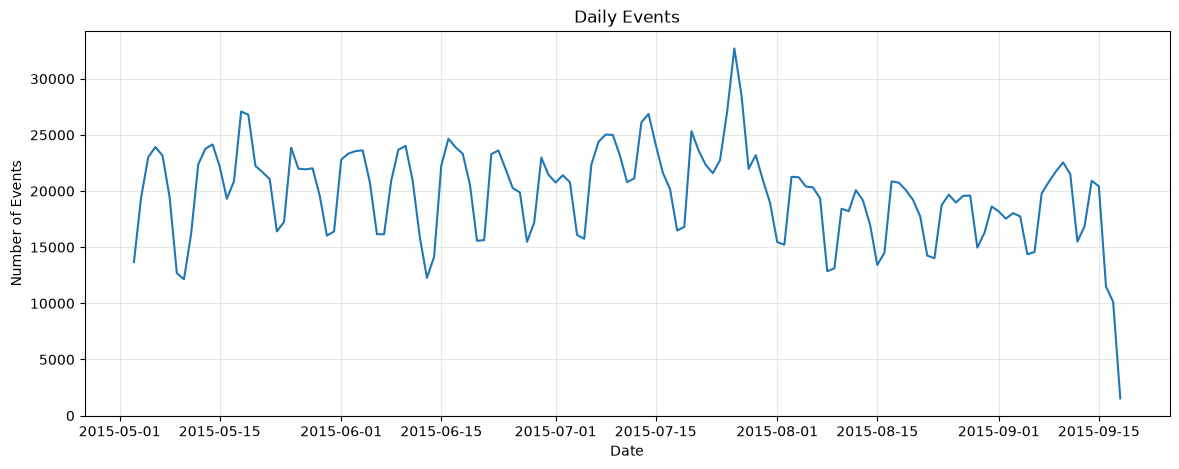

In [34]:
import matplotlib.pyplot as plt

daily_activity["total_events"].plot(
    figsize=(14, 5),
    title="Daily Events"
)

plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.show()

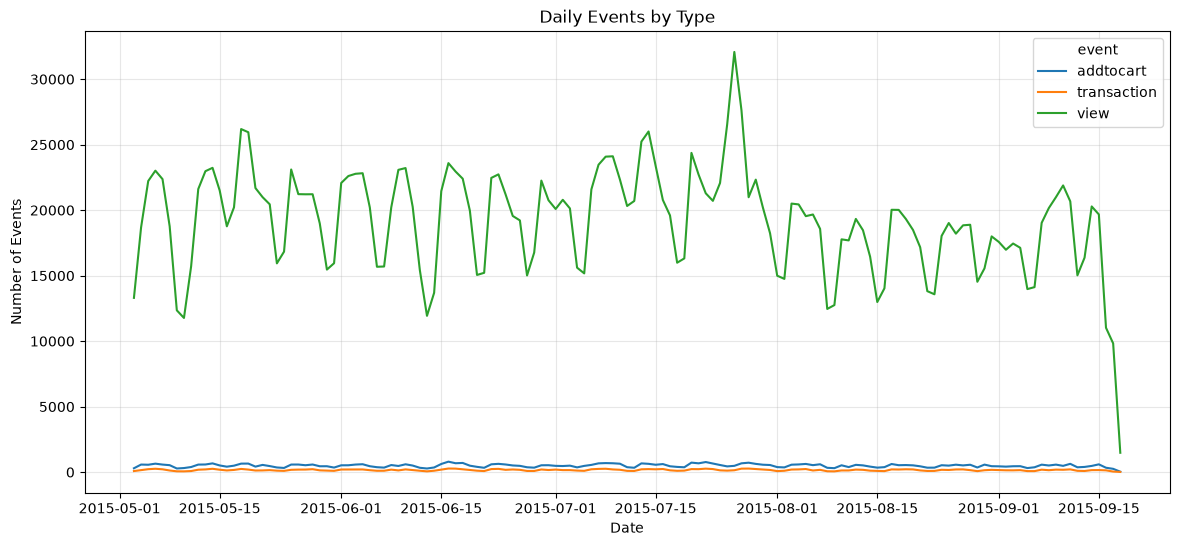

In [35]:
daily_events.plot(
    figsize=(14, 6),
    title="Daily Events by Type"
)

plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.grid(alpha=0.3)
plt.show()

In [36]:
daily_activity.nsmallest(10, "total_events")

,total_events,unique_users,unique_items
date,,,
2015-09-18,1528,1016,1204
2015-09-17,10128,6270,6973
2015-09-16,11495,6824,7723
2015-05-10,12143,7413,8030
2015-06-13,12270,7465,8221
2015-05-09,12695,7610,8199
2015-08-08,12857,8272,8485
2015-08-09,13117,8588,8778
2015-08-15,13423,8493,8904


In [37]:
daily_activity.tail(10)

,total_events,unique_users,unique_items
date,,,
2015-09-09,21761,13066,13314
2015-09-10,22548,14075,13665
2015-09-11,21517,13080,12710
2015-09-12,15496,9944,9877
2015-09-13,16859,10768,10823
2015-09-14,20913,13389,12892
2015-09-15,20427,12687,12272
2015-09-16,11495,6824,7723
2015-09-17,10128,6270,6973


In [38]:
daily_coverage = events_clean.groupby("date").agg(
    first_event=("datetime", "min"),
    last_event=("datetime", "max"),
    total_events=("event", "size")
)

daily_coverage.tail(10)

,first_event,last_event,total_events
date,,,
2015-09-09,2015-09-09 00:00:01.262+00:00,2015-09-09 23:59:48.572+00:00,21761
2015-09-10,2015-09-10 00:00:00.398+00:00,2015-09-10 23:59:54.555+00:00,22548
2015-09-11,2015-09-11 00:00:02.200+00:00,2015-09-11 23:59:51.336+00:00,21517
2015-09-12,2015-09-12 00:00:02.547+00:00,2015-09-12 23:59:47.942+00:00,15496
2015-09-13,2015-09-13 00:00:05.423+00:00,2015-09-13 23:59:56.743+00:00,16859
2015-09-14,2015-09-14 00:00:05.345+00:00,2015-09-14 23:59:45.566+00:00,20913
2015-09-15,2015-09-15 00:00:06.627+00:00,2015-09-15 23:59:58.763+00:00,20427
2015-09-16,2015-09-16 00:00:11.499+00:00,2015-09-16 23:59:58.436+00:00,11495
2015-09-17,2015-09-17 00:00:10.585+00:00,2015-09-17 23:59:55.623+00:00,10128


In [39]:
events_clean["hour"] = events_clean["datetime"].dt.hour

hourly_activity = events_clean.groupby("hour").agg(
    total_events=("event", "size"),
    unique_users=("visitorid", "nunique")
)

hourly_activity

,total_events,unique_users
hour,,
0,144303,89567
1,140702,88915
2,145879,92636
3,150860,96539
4,147184,93458
5,119572,75804
6,76972,49570
7,43944,28440
8,25309,16918


In [40]:
daily_by_event = events_clean.pivot_table(
    index="date",
    columns="event",
    values="visitorid",
    aggfunc="size",
    fill_value=0
)

from datetime import date

recent_activity = daily_by_event.loc[
    date(2015, 9, 9):date(2015, 9, 17)
]

recent_activity

event,addtocart,transaction,view
date,,,
2015-09-09,574,192,20995
2015-09-10,480,181,21887
2015-09-11,634,211,20672
2015-09-12,370,102,15024
2015-09-13,398,88,16373
2015-09-14,475,154,20284
2015-09-15,595,158,19674
2015-09-16,336,137,11022
2015-09-17,253,45,9830


In [41]:
recent_activity.pct_change() * 100

event,addtocart,transaction,view
date,,,
2015-09-09,NaN,NaN,NaN
2015-09-10,-16.38,-5.73,4.25
2015-09-11,32.08,16.57,-5.55
2015-09-12,-41.64,-51.66,-27.32
2015-09-13,7.57,-13.73,8.98
2015-09-14,19.35,75.00,23.89
2015-09-15,25.26,2.60,-3.01
2015-09-16,-43.53,-13.29,-43.98
2015-09-17,-24.70,-67.15,-10.81


In [42]:
from datetime import date


weekday_data = daily_by_event.loc[
    date(2015, 5, 4):date(2015, 9, 17)
].copy()

weekday_data["weekday"] = pd.to_datetime(
    weekday_data.index
).day_name()

weekday_summary = weekday_data.groupby("weekday")[
    ["view", "addtocart", "transaction"]
].agg(["median", "mean"])

weekday_summary

event         view          addtocart        transaction       
            median     mean    median   mean      median   mean
weekday                                                        
Friday    19217.00 19249.79    493.00 500.58      153.00 153.37
Monday    20976.50 21229.70    570.50 568.55      195.00 192.40
Saturday  15024.00 15602.89    370.00 365.74       98.00  95.32
Sunday    15557.00 16398.74    356.00 381.63       97.00 100.63
Thursday  20743.50 20203.00    543.00 547.55      206.00 187.50
Tuesday   21416.50 21575.95    579.00 579.25      198.50 198.65
Wednesday 21250.00 20778.95    576.50 569.20      206.50 207.55

In [43]:
weekday_median = weekday_data.groupby("weekday")[
    ["view", "addtocart", "transaction"]
].median()

for target_date in [date(2015, 9, 16), date(2015, 9, 17)]:
    weekday = pd.Timestamp(target_date).day_name()

    print(f"\n{target_date} ({weekday})")

    comparison = pd.DataFrame({
        "actual": weekday_data.loc[target_date, [
            "view", "addtocart", "transaction"
        ]],
        "weekday_median": weekday_median.loc[weekday]
    })

    comparison["deviation_%"] = (
        comparison["actual"] / comparison["weekday_median"] - 1
    ) * 100

    print(comparison.round(2))


2015-09-16 (Wednesday)
             actual  weekday_median  deviation_%
event                                           
view          11022        21250.00       -48.13
addtocart       336          576.50       -41.72
transaction     137          206.50       -33.66

2015-09-17 (Thursday)
             actual  weekday_median  deviation_%
event                                           
view           9830        20743.50       -52.61
addtocart       253          543.00       -53.41
transaction      45          206.00       -78.16


In [44]:
daily_event_metrics = (
    events_clean.groupby(["date", "event"])
    .agg(
        event_rows=("event", "size"),
        unique_users=("visitorid", "nunique"),
        unique_transactions=("transactionid", "nunique")
    )
    .reset_index()
)

daily_event_metrics[
    daily_event_metrics["date"].between(
        date(2015, 9, 9),
        date(2015, 9, 17)
    )
]

,date,event,event_rows,unique_users,unique_transactions
387,2015-09-09,addtocart,574,348,0
388,2015-09-09,transaction,192,120,159
389,2015-09-09,view,20995,13026,0
390,2015-09-10,addtocart,480,322,0
391,2015-09-10,transaction,181,108,138
392,2015-09-10,view,21887,14030,0
393,2015-09-11,addtocart,634,348,0
394,2015-09-11,transaction,211,106,140
395,2015-09-11,view,20672,13025,0
396,2015-09-12,addtocart,370,250,0
